# Analyse des ventes d'une boutique de quartier (2026)

Ce notebook complète le dashboard **Sales Insights** : l'application montre *ce qui s'est passé* (KPI, graphiques, filtres), ici on **interprète** les chiffres et on en tire des **recommandations**.

> **Données fictives** : le fichier `data/ventes-boutique-2026.csv` a été généré pour ce projet (boutique imaginaire, ventes de janvier à octobre 2026, en FCFA). Les conclusions illustrent une démarche d'analyse, pas une situation réelle.

**Plan** : 1. Chargement · 2. Nettoyage · 3. Indicateurs clés · 4. Évolution mensuelle · 5. Villes · 6. Catégories · 7. Produits · 8. Conclusions et recommandations

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt

BLEU = "#2a78d6"   # même bleu que le dashboard
GRIS = "#9aa5b1"

plt.rcParams.update({
    "figure.figsize": (8, 4.2),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.axisbelow": True,
})

def esp(n):
    """1679450 -> '1 679 450' (séparateur de milliers à la française)."""
    return f"{n:,.0f}".replace(",", " ")

def pct(x, signe=False):
    """32.4 -> '32,4 %' (virgule décimale à la française)."""
    texte = f"{x:+.1f}" if signe else f"{x:.1f}"
    return texte.replace(".", ",") + " %"

## 1. Chargement

Le fichier est au format français : séparateur `;`, dates `jj/mm/aaaa`, prix parfois écrits `14 500` ou `2500 FCFA`. On lit tout en texte (`dtype=str`) pour garder la main sur la conversion.

In [2]:
brut = pd.read_csv("data/ventes-boutique-2026.csv", sep=";", dtype=str)
print(f"{len(brut)} lignes, colonnes : {list(brut.columns)}")
brut.head(8)

444 lignes, colonnes : ['Date', 'Produit', 'Catégorie', 'Quantité', 'Prix unitaire', 'Ville']


,Date,Produit,Catégorie,Quantité,Prix unitaire,Ville
0,24/05/2026,Balai,Maison,1,1500,Dakar
1,06/09/2026,Câble USB,Téléphonie,5,2000,Dakar
2,15/06/2026,Crédit de recharge 5000,Téléphonie,8,5000,Dakar
3,16/04/2026,Câble USB,Téléphonie,5,2000,Dakar
4,27/04/2026,Coque de téléphone,Téléphonie,6,2500 FCFA,Mbour
5,21/07/2026,Riz brisé 25kg,Alimentation,3,14500 FCFA,Mbour
6,19/09/2026,"Eau minérale 1,5L",Boissons,6,500 FCFA,Dakar
7,10/07/2026,Câble USB,Téléphonie,1,2000,Thiès


## 2. Nettoyage

On applique les **mêmes règles que l'application** (`lib/cleanData.js`), dans le même ordre : valeurs manquantes, dates invalides, quantités invalides, prix invalides, puis doublons. Une ligne est rejetée pour la première raison rencontrée.

In [3]:
def en_nombre(valeur):
    """'14 500', '2500 FCFA', '2,5' -> nombre. Renvoie None si invalide."""
    if pd.isna(valeur):
        return None
    texte = re.sub(r"[^\d,.\-\s]", "", str(valeur))   # retire devises et lettres
    texte = re.sub(r"\s", "", texte)                    # retire les espaces
    if "," in texte and "." not in texte:
        texte = texte.replace(",", ".")                 # virgule décimale
    else:
        texte = texte.replace(",", "")
    try:
        return float(texte)
    except ValueError:
        return None

def nettoyer_texte(serie):
    return serie.fillna("").str.strip().str.replace(r"\s+", " ", regex=True)

df = pd.DataFrame({
    "date": pd.to_datetime(brut["Date"].str.strip(), format="%d/%m/%Y", errors="coerce"),
    "produit": nettoyer_texte(brut["Produit"]).str.capitalize(),
    "categorie": nettoyer_texte(brut["Catégorie"]).str.capitalize(),
    "quantite": brut["Quantité"].map(en_nombre),
    "prix": brut["Prix unitaire"].map(en_nombre),
    "ville": nettoyer_texte(brut["Ville"]).str.title(),
})

In [4]:
n_depart = len(df)
rapport = {}

# 1. valeurs manquantes
date_vide = brut["Date"].fillna("").str.strip() == ""
manquant = date_vide | (df["produit"] == "") | (df["categorie"] == "") | (df["ville"] == "")
rapport["Valeurs manquantes"] = int(manquant.sum())
df = df[~manquant]

# 2. dates invalides (ex. 31/02/2026, « hier »)
date_invalide = df["date"].isna()
rapport["Dates invalides"] = int(date_invalide.sum())
df = df[~date_invalide]

# 3. quantités : entier strictement positif
qte_invalide = ~(df["quantite"] > 0) | (df["quantite"] % 1 != 0)
rapport["Quantités invalides"] = int(qte_invalide.sum())
df = df[~qte_invalide]

# 4. prix : nombre positif ou nul
prix_invalide = df["prix"].isna() | (df["prix"] < 0)
rapport["Prix invalides"] = int(prix_invalide.sum())
df = df[~prix_invalide]

# 5. doublons exacts
colonnes = ["date", "produit", "categorie", "quantite", "prix", "ville"]
doublons = df.duplicated(subset=colonnes)
rapport["Doublons"] = int(doublons.sum())
df = df[~doublons].copy()

# colonnes utiles pour la suite
df["quantite"] = df["quantite"].astype(int)
df["total"] = df["quantite"] * df["prix"]
df["mois"] = df["date"].dt.to_period("M")
df = df.sort_values("date").reset_index(drop=True)

print(f"Lignes lues         : {n_depart}")
for nom, n in rapport.items():
    print(f"{nom:<20}: {n}")
print(f"Lignes gardées      : {len(df)} ({pct(len(df) / n_depart * 100)})")
print(f"Période             : du {df['date'].min():%d/%m/%Y} au {df['date'].max():%d/%m/%Y}")
print()
print("Même résultat que l'application (423 lignes gardées) :", len(df) == 423)

Lignes lues         : 444
Valeurs manquantes  : 5
Dates invalides     : 2
Quantités invalides : 3
Prix invalides      : 2
Doublons            : 9
Lignes gardées      : 423 (95,3 %)
Période             : du 07/01/2026 au 24/10/2026

Même résultat que l'application (423 lignes gardées) : True


## 3. Indicateurs clés

Mêmes définitions que dans le dashboard : le **panier moyen** est le chiffre d'affaires divisé par le nombre de ventes (une ligne = une vente).

In [5]:
ca = df["total"].sum()
nb_ventes = len(df)
unites = int(df["quantite"].sum())
panier_moyen = ca / nb_ventes

print(f"Chiffre d'affaires : {esp(ca)} FCFA")
print(f"Nombre de ventes   : {nb_ventes}")
print(f"Unités vendues     : {esp(unites)}")
print(f"Panier moyen       : {esp(panier_moyen)} FCFA")

Chiffre d'affaires : 5 187 800 FCFA
Nombre de ventes   : 423
Unités vendues     : 1 796
Panier moyen       : 12 264 FCFA


## 4. Évolution mensuelle

Attention : les données s'arrêtent en **octobre avant la fin du mois**. Comparer octobre à septembre tel quel est trompeur, donc on calcule aussi le chiffre d'affaires **par jour observé**.

In [6]:
MOIS = ["janv.", "févr.", "mars", "avr.", "mai", "juin", "juil.", "août", "sept.", "oct.", "nov.", "déc."]

mensuel = df.groupby("mois").agg(ca=("total", "sum"), ventes=("total", "size"))
mensuel["jours"] = [p.days_in_month for p in mensuel.index]
mensuel.loc[mensuel.index[-1], "jours"] = df["date"].max().day   # dernier mois incomplet
mensuel["ca_par_jour"] = mensuel["ca"] / mensuel["jours"]

tableau = pd.DataFrame({
    "Mois": [MOIS[p.month - 1] for p in mensuel.index],
    "CA (FCFA)": mensuel["ca"].map(esp).values,
    "Ventes": mensuel["ventes"].values,
    "Jours observés": mensuel["jours"].values,
    "CA par jour": mensuel["ca_par_jour"].map(esp).values,
})
tableau

,Mois,CA (FCFA),Ventes,Jours observés,CA par jour
0,janv.,216 000,18,31,6 968
1,févr.,401 600,29,28,14 343
2,mars,498 700,38,31,16 087
3,avr.,844 050,69,30,28 135
4,mai,471 400,43,31,15 206
5,juin,515 000,46,30,17 167
6,juil.,639 600,53,31,20 632
7,août,605 550,39,31,19 534
8,sept.,635 850,52,30,21 195
9,oct.,360 050,36,24,15 002


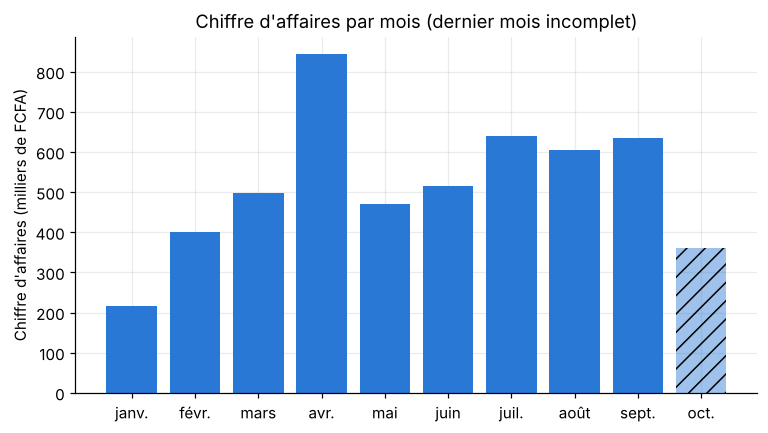

In [7]:
labels = [MOIS[p.month - 1] for p in mensuel.index]
fig, ax = plt.subplots()
barres = ax.bar(labels, mensuel["ca"] / 1000, color=BLEU)
barres[-1].set_alpha(0.45)          # dernier mois incomplet
barres[-1].set_hatch("//")
ax.set_ylabel("Chiffre d'affaires (milliers de FCFA)")
ax.set_title("Chiffre d'affaires par mois (dernier mois incomplet)")
plt.show()

In [8]:
dernier, precedent = mensuel.iloc[-1], mensuel.iloc[-2]
croissance_brute = (dernier["ca"] / precedent["ca"] - 1) * 100
croissance_par_jour = (dernier["ca_par_jour"] / precedent["ca_par_jour"] - 1) * 100

print(f"Octobre vs septembre, brut             : {pct(croissance_brute, True)}")
print(f"Octobre vs septembre, par jour observé : {pct(croissance_par_jour, True)}")

Octobre vs septembre, brut             : -43,4 %
Octobre vs septembre, par jour observé : -29,2 %


## 5. Villes

Où se fait le chiffre d'affaires, et le panier moyen change-t-il d'une ville à l'autre ?

In [9]:
villes = df.groupby("ville").agg(
    ca=("total", "sum"), ventes=("total", "size"), panier=("total", "mean")
).sort_values("ca", ascending=False)
villes["part"] = villes["ca"] / ca * 100

pd.DataFrame({
    "CA (FCFA)": villes["ca"].map(esp),
    "Part du CA": villes["part"].map(pct),
    "Ventes": villes["ventes"],
    "Panier moyen": villes["panier"].map(esp),
})

,CA (FCFA),Part du CA,Ventes,Panier moyen
ville,,,,
Dakar,1 679 450,"32,4 %",140,11 996
Thiès,1 251 350,"24,1 %",102,12 268
Kaolack,639 100,"12,3 %",51,12 531
Touba,545 800,"10,5 %",45,12 129
Saint-Louis,539 150,"10,4 %",40,13 479
Mbour,532 950,"10,3 %",45,11 843


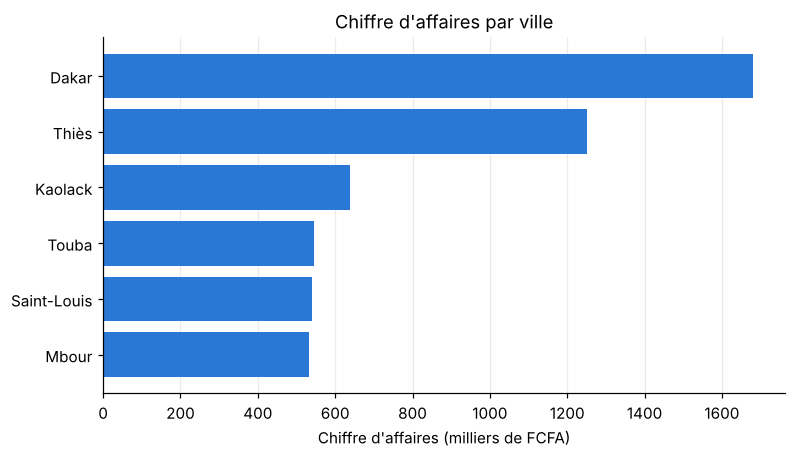

In [10]:
fig, ax = plt.subplots()
ordre = villes.sort_values("ca")
ax.barh(ordre.index, ordre["ca"] / 1000, color=BLEU)
ax.set_xlabel("Chiffre d'affaires (milliers de FCFA)")
ax.set_title("Chiffre d'affaires par ville")
ax.grid(axis="y", visible=False)
plt.show()

## 6. Catégories

Une catégorie qui vend beaucoup de fois n'est pas forcément celle qui rapporte le plus : on compare la **part des ventes** et la **part du chiffre d'affaires**.

In [11]:
categories = df.groupby("categorie").agg(
    ca=("total", "sum"), ventes=("total", "size"), panier=("total", "mean")
).sort_values("ca", ascending=False)
categories["part_ca"] = categories["ca"] / ca * 100
categories["part_ventes"] = categories["ventes"] / nb_ventes * 100

pd.DataFrame({
    "CA (FCFA)": categories["ca"].map(esp),
    "Part du CA": categories["part_ca"].map(pct),
    "Ventes": categories["ventes"],
    "Part des ventes": categories["part_ventes"].map(pct),
    "Panier moyen": categories["panier"].map(esp),
})

,CA (FCFA),Part du CA,Ventes,Part des ventes,Panier moyen
categorie,,,,,
Maison,1 412 300,"27,2 %",78,"18,4 %",18 106
Alimentation,1 283 800,"24,7 %",126,"29,8 %",10 189
Papeterie,1 239 800,"23,9 %",66,"15,6 %",18 785
Téléphonie,969 500,"18,7 %",74,"17,5 %",13 101
Boissons,282 400,"5,4 %",79,"18,7 %",3 575


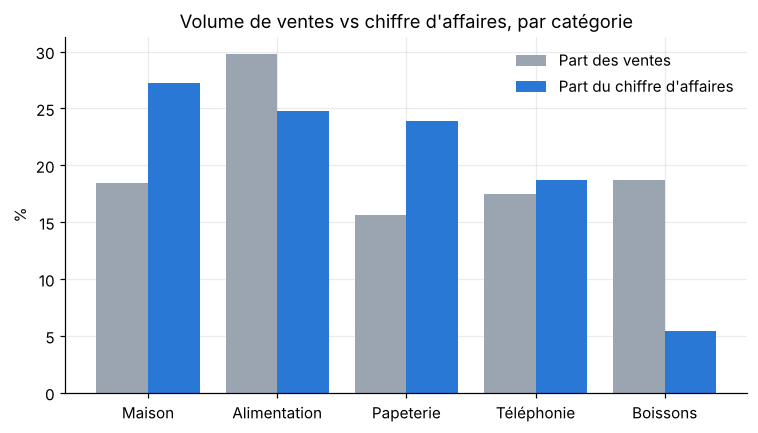

In [12]:
import numpy as np

ordre = categories.sort_values("part_ca", ascending=False)
x = np.arange(len(ordre))
fig, ax = plt.subplots()
ax.bar(x - 0.2, ordre["part_ventes"], width=0.4, color=GRIS, label="Part des ventes")
ax.bar(x + 0.2, ordre["part_ca"], width=0.4, color=BLEU, label="Part du chiffre d'affaires")
ax.set_xticks(x)
ax.set_xticklabels(ordre.index)
ax.set_ylabel("%")
ax.set_title("Volume de ventes vs chiffre d'affaires, par catégorie")
ax.legend(frameon=False)
plt.show()

## 7. Produits

Quelques produits font-ils l'essentiel du chiffre d'affaires ? (principe de Pareto)

In [13]:
produits = df.groupby("produit")["total"].sum().sort_values(ascending=False)
part_cumulee = produits.cumsum() / ca * 100

pd.DataFrame({
    "CA (FCFA)": produits.map(esp),
    "Part du CA": (produits / ca * 100).map(pct),
    "Part cumulée": part_cumulee.map(pct),
}).head(10)

,CA (FCFA),Part du CA,Part cumulée
produit,,,
Cartable,1 007 000,"19,4 %","19,4 %"
Bouilloire,882 000,"17,0 %","36,4 %"
Riz brisé 25kg,594 500,"11,5 %","47,9 %"
Huile d'arachide 5l,487 500,"9,4 %","57,3 %"
Natte,315 000,"6,1 %","63,3 %"
Crédit de recharge 5000,300 000,"5,8 %","69,1 %"
Écouteurs filaires,255 000,"4,9 %","74,0 %"
Coque de téléphone,252 500,"4,9 %","78,9 %"
Stylo bleu (lot de 10),163 500,"3,2 %","82,1 %"


In [14]:
n_produits = len(produits)
n_top = max(1, round(n_produits * 0.2))
part_top = produits.head(n_top).sum() / ca * 100
print(f"{n_produits} produits au total.")
print(f"Les {n_top} premiers (20 %) réalisent {pct(part_top)} du chiffre d'affaires :")
print(", ".join(produits.head(n_top).index))

21 produits au total.
Les 4 premiers (20 %) réalisent 57,3 % du chiffre d'affaires :
Cartable, Bouilloire, Riz brisé 25kg, Huile d'arachide 5l


## 8. Conclusions et recommandations

**Ce que disent les chiffres**

1. **Le chiffre d'affaires est concentré sur deux villes.** Dakar et Thiès réalisent 56,5 % du total (32,4 % et 24,1 %). Les quatre autres villes pèsent chacune entre 10,3 % et 12,3 %.
2. **Le panier moyen varie peu d'une ville à l'autre** (11 843 à 13 479 FCFA). Saint-Louis a le plus élevé, mais sur seulement 40 ventes, et ses ventes sont dominées par la catégorie Papeterie (40,2 % de son chiffre d'affaires) : l'écart est à confirmer avant d'en tirer une conclusion.
3. **Volume et valeur ne vont pas ensemble.** Les Boissons représentent 18,7 % des ventes mais seulement 5,4 % du chiffre d'affaires (panier moyen de 3 575 FCFA).
4. **Un petit nombre de produits porte l'activité.** Les 4 premiers produits sur 21 (Cartable, Bouilloire, Riz brisé 25kg, Huile d'arachide 5l) font 57,3 % du chiffre d'affaires, et Cartable et Bouilloire à eux deux 36,4 %.
5. **Avril est un pic.** 844 050 FCFA, soit +74 % par rapport à la moyenne de mars et mai, avec 69 ventes contre 38 et 43 : c'est surtout le nombre de ventes qui augmente. Les données seules ne disent pas pourquoi (promotion, événement, saisie groupée ?) : c'est à vérifier avec le commerçant.
6. **Octobre est incomplet.** Comparé brut à septembre, il semble reculer de 43 % ; corrigé du nombre de jours observés, l'écart est de -29 %.

**Recommandations (pour la boutique imaginaire)**

- Ne jamais être en rupture sur les produits du haut du classement (Cartable, Bouilloire, Riz brisé 25kg, Huile d'arachide 5l).
- Chercher ce qui s'est passé en avril et, si c'est une action reproductible (promotion, offre), la renouveler.
- Ne pas pousser les Boissons sans connaître leur marge : elles font du volume, mais peu de chiffre d'affaires.
- Comprendre pourquoi les quatre autres villes restent autour de 10 % chacune (clientèle, stock, nombre de points de vente) avant de décider d'y investir.

**Limites de l'analyse**

- Données fictives : les conclusions servent d'illustration.
- Pas de prix d'achat : on mesure le chiffre d'affaires, pas le bénéfice.
- Dix mois seulement : impossible de parler de saisonnalité annuelle.
- Sur de petits effectifs (par ville ou par produit), des écarts peuvent être dus au hasard.

**Pistes pour aller plus loin** : ajouter les coûts pour calculer la marge, comparer avec une autre année, tester si les écarts entre villes sont statistiquement significatifs, puis prévoir les ventes des prochains mois.

**Retour sur l'application** : l'indicateur « croissance mensuelle » de Sales Insights compare le dernier mois au précédent (`lib/analytics.js`) sans tenir compte d'un mois incomplet. Sur ce fichier, il afficherait -43,4 % alors que la variation par jour observé est de -29,2 %. Signaler les mois incomplets serait une amélioration utile.